# Task 3: Model Selection and Training

For this project, I selected EfficientNet-B0 as the main classification model. It is a relatively lightweight convolutional neural network that provides a good balance between accuracy and training cost. I used a version pretrained on ImageNet so the model already understands useful visual features such as shapes, edges, colours, and textures.

The original output layer is replaced with a new layer containing eight outputs, one for each facial-feature class. I will first train the new classification layer while keeping the pretrained feature-extraction layers frozen. After that, part of the model can be fine-tuned using a smaller learning rate.

Project root: /Users/amanm/Documents/KAGGLE/ENGE707-Facial-Feature-Classification
Labels shape: (63660, 2)
Training directory exists: True


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


Checking duplicates:   0%|          | 0/63660 [00:00<?, ?it/s]

Original images: 63660
Duplicate images excluded: 15
Images remaining: 63645
Training images: 50916
Validation images: 12729


,training,validation
class,,
CatEye,11102,2775
CatFace,5553,1389
CatMouth,5553,1388
CatNose,5553,1388
DogEye,9261,2315
DogFace,4630,1158
DogMouth,4632,1158
DogNose,4632,1158


Image size: 224
Class mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Training dataset size: 50916
Validation dataset size: 12729
Training batches: 1592
Validation batches: 398
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


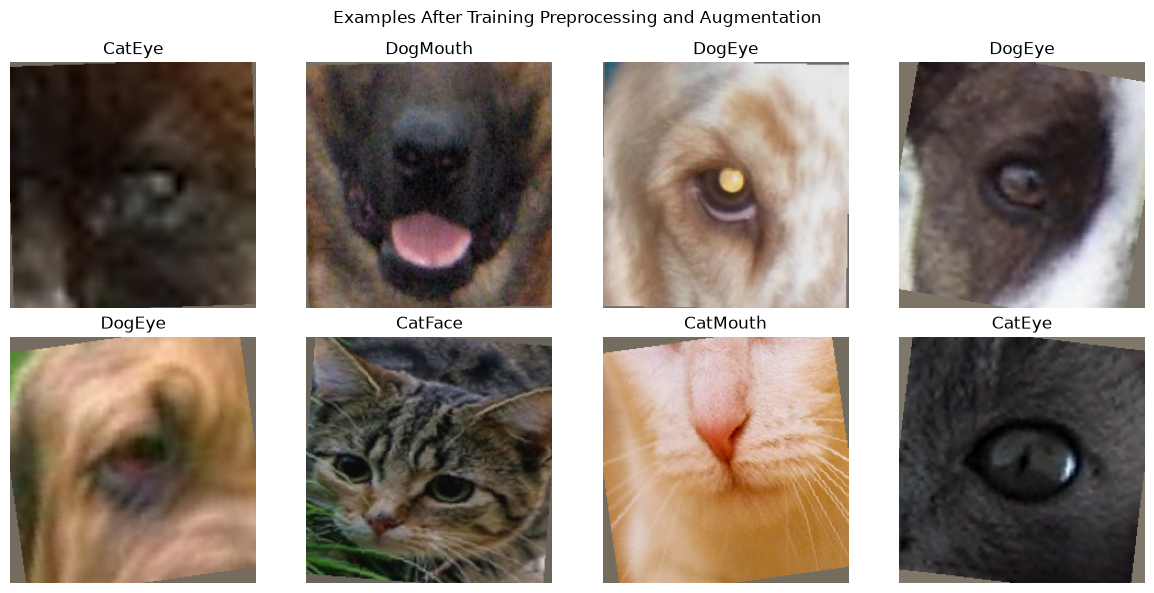

Preprocessing loaded successfully.
Training batches: 1592
Validation batches: 398
Classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


In [3]:
%run 02_preprocessing.ipynb

print("Preprocessing loaded successfully.")
print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Classes:", class_names)

In [14]:
import ssl
import certifi

ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

print("SSL certificate configuration updated.")

SSL certificate configuration updated.


In [19]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

weights_path = PROJECT_ROOT / "models" / "efficientnet_b0_imagenet.pth"

try:
    # Normal method used on computers with a working connection
    model = efficientnet_b0(
        weights=EfficientNet_B0_Weights.DEFAULT
    )
    print("Loaded pretrained weights automatically.")

except Exception:
    # Fallback for the certificate problem on this Mac
    if not weights_path.exists():
        raise FileNotFoundError(
            "The pretrained weights could not be downloaded and "
            "the local fallback file is missing."
        )

    model = efficientnet_b0(weights=None)

    state_dict = torch.load(
        weights_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(state_dict)
    print("Loaded pretrained weights from the local fallback.")

# Freeze the pretrained feature extractor
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Replace the original 1,000-class output with eight classes
input_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.30),
    nn.Linear(input_features, len(class_names))
)

model = model.to(device)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Device:", device)
print("Number of output classes:", len(class_names))
print("Trainable parameters:", f"{trainable_parameters:,}")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /Users/amanm/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
Loaded pretrained weights from the local fallback.
Device: mps
Number of output classes: 8
Trainable parameters: 10,248
Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=8, bias=True)
)


In [20]:
training_counts = (
    train_data["class"]
    .value_counts()
    .reindex(class_names)
)

class_weights = len(train_data) / (
    len(class_names) * training_counts
)

class_weights_tensor = torch.tensor(
    class_weights.values,
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor,
    label_smoothing=0.05
)

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Class weights:")
display(class_weights.to_frame(name="weight"))

print("Loss function:", criterion)
print("Optimiser:", optimizer.__class__.__name__)

Class weights:


,weight
class,
CatEye,0.573275
CatFace,1.146137
CatMouth,1.146137
CatNose,1.146137
DogEye,0.687237
DogFace,1.374622
DogMouth,1.374028
DogNose,1.374028


Loss function: CrossEntropyLoss()
Optimiser: AdamW


In [29]:
from tqdm.auto import tqdm

def train_one_epoch(model, data_loader, criterion, optimizer, device):
    model.train()
    for block in model.features[:-2]:
        block.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    progress = tqdm(data_loader, desc="Training", leave=False)

    for images, labels_batch in progress:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        correct_predictions += (
            outputs.argmax(dim=1) == labels_batch
        ).sum().item()
        total_samples += batch_size

        progress.set_postfix(loss=f"{loss.item():.4f}")

    return (
        total_loss / total_samples,
        correct_predictions / total_samples
    )


@torch.no_grad()
def evaluate_model(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    progress = tqdm(data_loader, desc="Validation", leave=False)

    for images, labels_batch in progress:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels_batch)

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        correct_predictions += (
            outputs.argmax(dim=1) == labels_batch
        ).sum().item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        correct_predictions / total_samples
    )

print("Training and validation functions are ready.")

Training and validation functions are ready.


In [24]:
model.train()

test_images, test_labels = next(iter(train_loader))
test_images = test_images.to(device)
test_labels = test_labels.to(device)

test_outputs = model(test_images)
test_loss = criterion(test_outputs, test_labels)

print("Input shape:", test_images.shape)
print("Output shape:", test_outputs.shape)
print("Test loss:", round(test_loss.item(), 4))

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 8])
Test loss: 2.1885


In [25]:
import time

HEAD_EPOCHS = 3
best_validation_accuracy = 0.0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

best_model_path = MODELS_DIR / "efficientnet_b0_best.pth"

for epoch in range(HEAD_EPOCHS):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    validation_loss, validation_accuracy = evaluate_model(
        model,
        validation_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "validation_accuracy": validation_accuracy,
            "epoch": epoch + 1
        }, best_model_path)

    elapsed_minutes = (time.time() - start_time) / 60

    print(
        f"Epoch {epoch + 1}/{HEAD_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Validation loss: {validation_loss:.4f} | "
        f"Validation accuracy: {validation_accuracy:.4f} | "
        f"Time: {elapsed_minutes:.1f} minutes"
    )

print("\nBest validation accuracy:", round(best_validation_accuracy, 4))
print("Best model saved to:", best_model_path)

Training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

Epoch 1/3 | Train loss: 0.9493 | Train accuracy: 0.7440 | Validation loss: 0.8386 | Validation accuracy: 0.7833 | Time: 5.3 minutes


Training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

Epoch 2/3 | Train loss: 0.8384 | Train accuracy: 0.7843 | Validation loss: 0.8085 | Validation accuracy: 0.7985 | Time: 5.3 minutes


Training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

Epoch 3/3 | Train loss: 0.8286 | Train accuracy: 0.7908 | Validation loss: 0.7863 | Validation accuracy: 0.8148 | Time: 5.2 minutes

Best validation accuracy: 0.8148
Best model saved to: /Users/amanm/Documents/KAGGLE/ENGE707-Facial-Feature-Classification/models/efficientnet_b0_best.pth


In [27]:
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Keep most of the network frozen
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Fine-tune only the final two feature blocks
for parameter in model.features[-2:].parameters():
    parameter.requires_grad = True

fine_tune_optimizer = torch.optim.AdamW([
    {
        "params": model.features[-2:].parameters(),
        "lr": 0.00001
    },
    {
        "params": model.classifier.parameters(),
        "lr": 0.0001
    }
], weight_decay=0.0001)

fine_tune_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Starting validation accuracy:", checkpoint["validation_accuracy"])
print("Fine-tuning parameters:", f"{fine_tune_parameters:,}")

Checkpoint epoch: 3
Starting validation accuracy: 0.814753711996229
Fine-tuning parameters: 1,139,640


In [30]:
FINE_TUNE_EPOCHS = 3
best_validation_accuracy = checkpoint["validation_accuracy"]

for epoch in range(FINE_TUNE_EPOCHS):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        fine_tune_optimizer,
        device
    )

    validation_loss, validation_accuracy = evaluate_model(
        model,
        validation_loader,
        criterion,
        device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "validation_accuracy": validation_accuracy,
            "epoch": HEAD_EPOCHS + epoch + 1
        }, best_model_path)

    elapsed_minutes = (time.time() - start_time) / 60

    print(
        f"Fine-tune epoch {epoch + 1}/{FINE_TUNE_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Validation loss: {validation_loss:.4f} | "
        f"Validation accuracy: {validation_accuracy:.4f} | "
        f"Time: {elapsed_minutes:.1f} minutes"
    )

print("\nBest validation accuracy:", round(best_validation_accuracy, 4))
print("Best model saved to:", best_model_path)

Training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

Fine-tune epoch 1/3 | Train loss: 0.7328 | Train accuracy: 0.8348 | Validation loss: 0.6720 | Validation accuracy: 0.8591 | Time: 5.2 minutes


Training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

Fine-tune epoch 2/3 | Train loss: 0.6596 | Train accuracy: 0.8665 | Validation loss: 0.6210 | Validation accuracy: 0.8832 | Time: 5.2 minutes


Training:   0%|          | 0/1592 [00:00<?, ?it/s]

Validation:   0%|          | 0/398 [00:00<?, ?it/s]

Fine-tune epoch 3/3 | Train loss: 0.6161 | Train accuracy: 0.8877 | Validation loss: 0.5846 | Validation accuracy: 0.9017 | Time: 5.1 minutes

Best validation accuracy: 0.9017
Best model saved to: /Users/amanm/Documents/KAGGLE/ENGE707-Facial-Feature-Classification/models/efficientnet_b0_best.pth


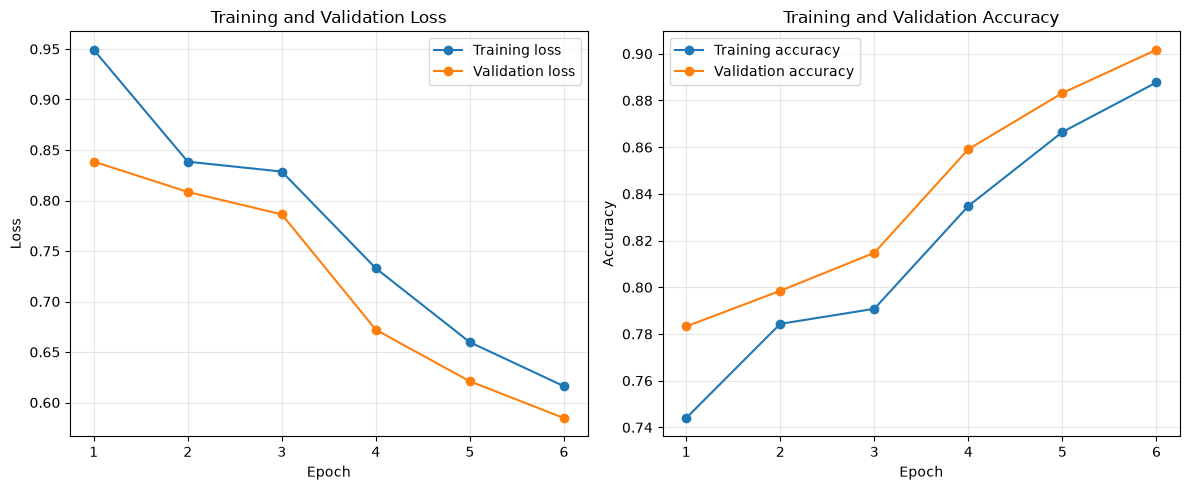

In [31]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training loss"
)
axes[0].plot(
    epochs,
    history["validation_loss"],
    marker="o",
    label="Validation loss"
)
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training accuracy"
)
axes[1].plot(
    epochs,
    history["validation_accuracy"],
    marker="o",
    label="Validation accuracy"
)
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [32]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

best_checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels_batch in tqdm(
        validation_loader,
        desc="Evaluating best model"
    ):
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu()

        true_labels.extend(labels_batch.numpy())
        predicted_labels.extend(predictions.numpy())

validation_accuracy = accuracy_score(
    true_labels,
    predicted_labels
)

balanced_validation_accuracy = balanced_accuracy_score(
    true_labels,
    predicted_labels
)

print("Validation accuracy:", round(validation_accuracy, 4))
print(
    "Balanced validation accuracy:",
    round(balanced_validation_accuracy, 4)
)

print("\nClassification report:")
print(classification_report(
    true_labels,
    predicted_labels,
    target_names=class_names,
    digits=4
))

Evaluating best model:   0%|          | 0/398 [00:00<?, ?it/s]

Validation accuracy: 0.9017
Balanced validation accuracy: 0.9001

Classification report:
              precision    recall  f1-score   support

      CatEye     0.9512    0.9409    0.9460      2775
     CatFace     0.9892    0.9899    0.9896      1389
    CatMouth     0.8013    0.9207    0.8569      1388
     CatNose     0.8632    0.7731    0.8157      1388
      DogEye     0.9259    0.8639    0.8939      2315
     DogFace     0.9194    0.9758    0.9468      1158
    DogMouth     0.8424    0.8955    0.8681      1158
     DogNose     0.8574    0.8411    0.8492      1158

    accuracy                         0.9017     12729
   macro avg     0.8938    0.9001    0.8958     12729
weighted avg     0.9035    0.9017    0.9015     12729



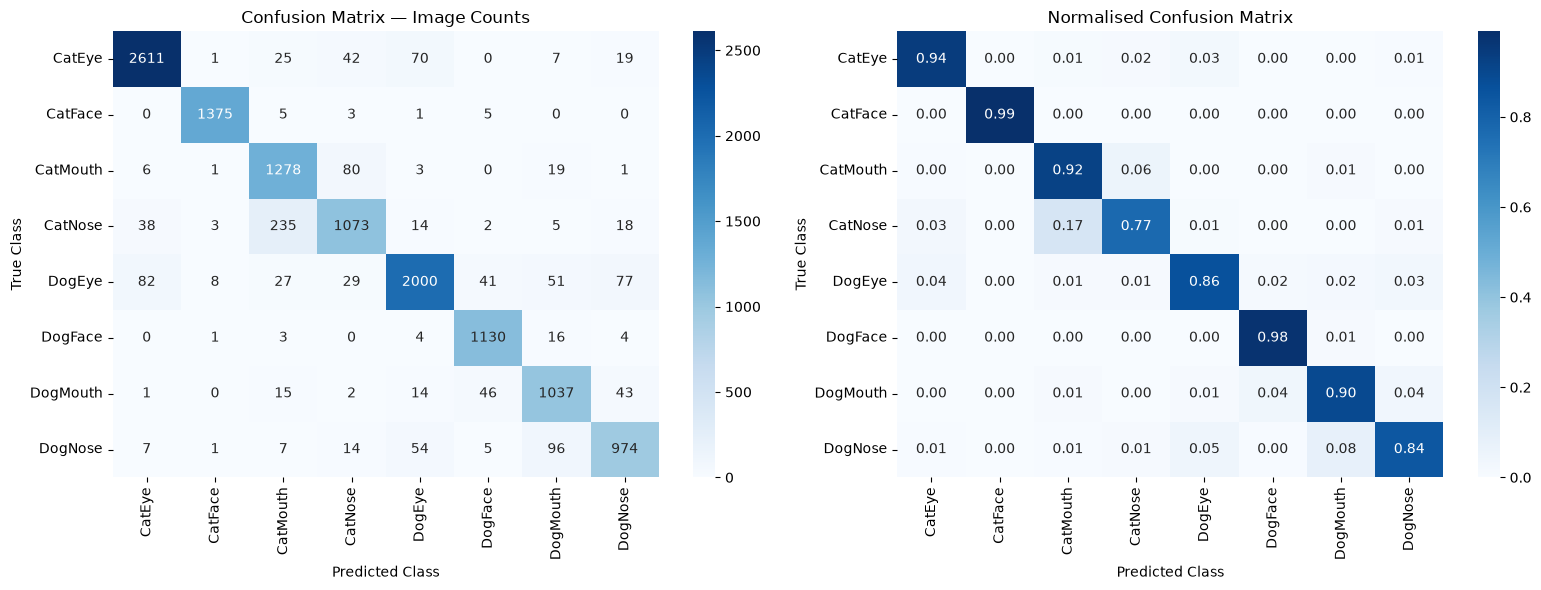

In [33]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(
    true_labels,
    predicted_labels
)

normalised_confusion = confusion_matrix(
    true_labels,
    predicted_labels,
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix — Image Counts")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

sns.heatmap(
    normalised_confusion,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)
axes[1].set_title("Normalised Confusion Matrix")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Training and Validation Summary

I trained EfficientNet-B0 in two stages. During the first three epochs, I kept the pretrained feature extractor frozen and trained only the new eight-class output layer. This produced a validation accuracy of 81.48%.

I then unfroze the final two feature blocks and fine-tuned them for another three epochs using smaller learning rates. This improved the best validation accuracy to 90.17%, while the balanced accuracy reached 90.01%. The similar accuracy and balanced accuracy suggest that the model performs reasonably consistently across the differently sized classes.

The learning curves continued to improve throughout training, with decreasing training and validation loss and no clear sign of overfitting. CatFace and DogFace produced the strongest results. The most difficult class was CatNose, which was frequently confused with CatMouth. A similar but smaller pattern appeared between DogNose and DogMouth, most likely because close-up nose and mouth images can share similar shapes, colours, and surrounding facial features.